# Fase A — Análisis exploratorio del dataset
**Proyecto 2 y 3 — Estadísticas delictivas de Colombia 2025 (DIJIN)** · Grupo 7 · R.A. 2 y 3

## Contexto y punto de partida
En el Proyecto 1 se construyó una bodega con **480 091 casos** (un caso por fila). Para este proyecto el
problema es que **una fila por caso casi no tiene variables numéricas**: `CANTIDAD` vale 1 en todas las filas.
No se puede hacer un histograma, un boxplot ni una correlación sobre una constante.

Por eso el EDA trabaja sobre un **panel municipio × mes** (1 500 municipios × 12 meses = 18 000 filas),
donde sí hay variables numéricas con distribuciones reales:

| Variable | Qué mide |
|---|---|
| `casos` | casos registrados en el municipio ese mes |
| `casos_hurto`, `casos_vif`, `casos_homicidio`, `casos_otros` | casos por familia de delito |
| `dias_activos` | días del mes con al menos un caso |
| `pct_fin_semana` | % de casos ocurridos sábado o domingo |
| `pct_femenina` | % de víctimas mujeres (sobre casos con género conocido) |
| `edad_ordinal_media` | edad media de la víctima (0 = menor, 1 = adolescente, 2 = adulto) |
| `pct_arma_fuego`, `pct_sin_armas` | % de casos con arma de fuego / sin empleo de armas |

Esta fase es **exploratoria**: no modifica los datos (la limpieza es la Fase B).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

RAIZ = Path.cwd().parent if Path.cwd().name == "entrega" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from utilidades_delitos import cargar_datos_crudos, zanahoria_2026_panel_mensual  # noqa: E402

CARPETA_FIGURAS = RAIZ / "figuras"
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format

## 1. Carga de los datos

In [2]:
zanahoria_2026_df_crudo = cargar_datos_crudos(RAIZ / "datos")

# Carga mínima para explorar: se quitan los 40 renglones de pie de página y se interpreta la fecha.
# No se imputa ni se corrige nada todavía (eso es la Fase B).
zanahoria_2026_df_casos = zanahoria_2026_df_crudo.dropna(subset=["CODIGO DANE"]).copy()
zanahoria_2026_df_casos["fecha"] = pd.to_datetime(zanahoria_2026_df_casos["FECHA HECHO"], format="%d/%m/%Y")
zanahoria_2026_df_casos["dane"] = zanahoria_2026_df_casos["CODIGO DANE"].astype("int64")
zanahoria_2026_df_casos["departamento"] = zanahoria_2026_df_casos["DEPARTAMENTO"].str.upper()
zanahoria_2026_df_casos["municipio"] = (
    zanahoria_2026_df_casos["MUNICIPIO"].fillna("SIN ESPECIFICAR").str.replace(r"\s*\(CT\)", "", regex=True).str.upper()
)
zanahoria_2026_df_casos["tipo_delito"] = zanahoria_2026_df_casos["TIPO_DELITO"]
zanahoria_2026_df_casos["arma_grupo"] = zanahoria_2026_df_casos["ARMAS MEDIOS"]
zanahoria_2026_df_casos["genero"] = zanahoria_2026_df_casos["GENERO"]
zanahoria_2026_df_casos["edad"] = zanahoria_2026_df_casos["AGRUPA_EDAD_PERSONA"]

print(f"Casos: {len(zanahoria_2026_df_casos):,} | municipios (códigos DANE): {zanahoria_2026_df_casos['dane'].nunique():,} "
      f"| departamentos: {zanahoria_2026_df_casos['departamento'].nunique()} | rango de fechas: "
      f"{zanahoria_2026_df_casos['fecha'].min().date()} a {zanahoria_2026_df_casos['fecha'].max().date()}")
print("Valores distintos de CANTIDAD:", zanahoria_2026_df_casos["CANTIDAD"].unique())

Casos: 480,091 | municipios (códigos DANE): 1,500 | departamentos: 32 | rango de fechas: 2025-01-01 a 2025-12-31
Valores distintos de CANTIDAD: [1.]


## 2. Construcción del panel municipio × mes

In [3]:
zanahoria_2026_panel = zanahoria_2026_panel_mensual(zanahoria_2026_df_casos)

# Los porcentajes se calculan con las sumas de apoyo; quedan en NaN cuando no hay casos (o no hay dato de víctima)
p = zanahoria_2026_panel
zanahoria_2026_df_eda = pd.DataFrame({
    "dane": p["dane"], "departamento": p["departamento"], "municipio": p["municipio"], "mes": p["mes"],
    "casos": p["casos"], "casos_hurto": p["casos_hurto"], "casos_vif": p["casos_vif"],
    "casos_homicidio": p["casos_homicidio"], "casos_otros": p["casos_otros"], "dias_activos": p["dias_activos"],
    "pct_fin_semana": p["fin_sem"] / p["casos"].replace(0, np.nan),
    "pct_femenina": p["es_fem"] / p["tiene_genero"].replace(0, np.nan),
    "edad_ordinal_media": p["edad_ord"] / p["tiene_edad"].replace(0, np.nan),
    "pct_arma_fuego": p["es_fuego"] / p["casos"].replace(0, np.nan),
    "pct_sin_armas": p["es_sin_arma"] / p["casos"].replace(0, np.nan),
})
assert zanahoria_2026_df_eda["casos"].sum() == len(zanahoria_2026_df_casos)
print("Panel:", zanahoria_2026_df_eda.shape)

cols_conteo = ["casos", "casos_hurto", "casos_vif", "casos_homicidio", "casos_otros", "dias_activos"]
cols_pct = ["pct_fin_semana", "pct_femenina", "edad_ordinal_media", "pct_arma_fuego", "pct_sin_armas"]
zanahoria_2026_df_eda[cols_conteo + cols_pct].describe(percentiles=[.25, .5, .75, .95]).T

Panel: (18000, 15)


,count,mean,std,min,25%,50%,75%,95%,max
casos,"18,000.000",26.672,412.550,0.000,0.000,1.000,5.000,43.000,"18,567.000"
casos_hurto,"18,000.000",17.590,296.798,0.000,0.000,0.000,2.000,24.000,"13,323.000"
casos_vif,"18,000.000",7.853,112.924,0.000,0.000,0.000,2.000,16.000,"5,484.000"
casos_homicidio,"18,000.000",1.181,5.872,0.000,0.000,0.000,1.000,5.000,166.000
casos_otros,"18,000.000",0.048,0.857,0.000,0.000,0.000,0.000,0.000,75.000
dias_activos,"18,000.000",4.044,6.863,0.000,0.000,1.000,4.000,22.000,31.000
pct_fin_semana,"11,343.000",0.339,0.316,0.000,0.000,0.300,0.500,1.000,1.000
pct_femenina,"11,321.000",0.498,0.328,0.000,0.286,0.500,0.692,1.000,1.000
edad_ordinal_media,"11,323.000",1.954,0.181,0.000,2.000,2.000,2.000,2.000,2.000
pct_arma_fuego,"11,343.000",0.159,0.264,0.000,0.000,0.000,0.222,1.000,1.000


In [4]:
# ¿Qué tan completos están los datos? Los nulos de los porcentajes son "no hay casos ese mes", no errores
resumen_nulos = pd.DataFrame({
    "nulos": zanahoria_2026_df_eda[cols_conteo + cols_pct].isna().sum(),
    "% nulos": zanahoria_2026_df_eda[cols_conteo + cols_pct].isna().mean() * 100,
})
print(f"Municipio-mes sin ningún caso: {(zanahoria_2026_df_eda['casos'] == 0).mean():.1%}")
print(f"Municipio-mes con 10 o más casos: {(zanahoria_2026_df_eda['casos'] >= 10).mean():.1%}")
resumen_nulos[resumen_nulos["nulos"] > 0]

Municipio-mes sin ningún caso: 37.0%
Municipio-mes con 10 o más casos: 16.1%


,nulos,% nulos
pct_fin_semana,6657,36.983
pct_femenina,6679,37.106
edad_ordinal_media,6677,37.094
pct_arma_fuego,6657,36.983
pct_sin_armas,6657,36.983


## 3. Histogramas de las variables numéricas
Las variables de conteo están tan sesgadas (muchos municipios chicos, unas pocas capitales) que en escala
lineal se vería una sola barra. Se grafican en **escala log1p**. Los porcentajes se muestran solo para
municipios-mes con **10 o más casos**, porque con 1 o 2 casos un porcentaje solo puede ser 0 % o 100 % y
distorsiona la forma real de la distribución.

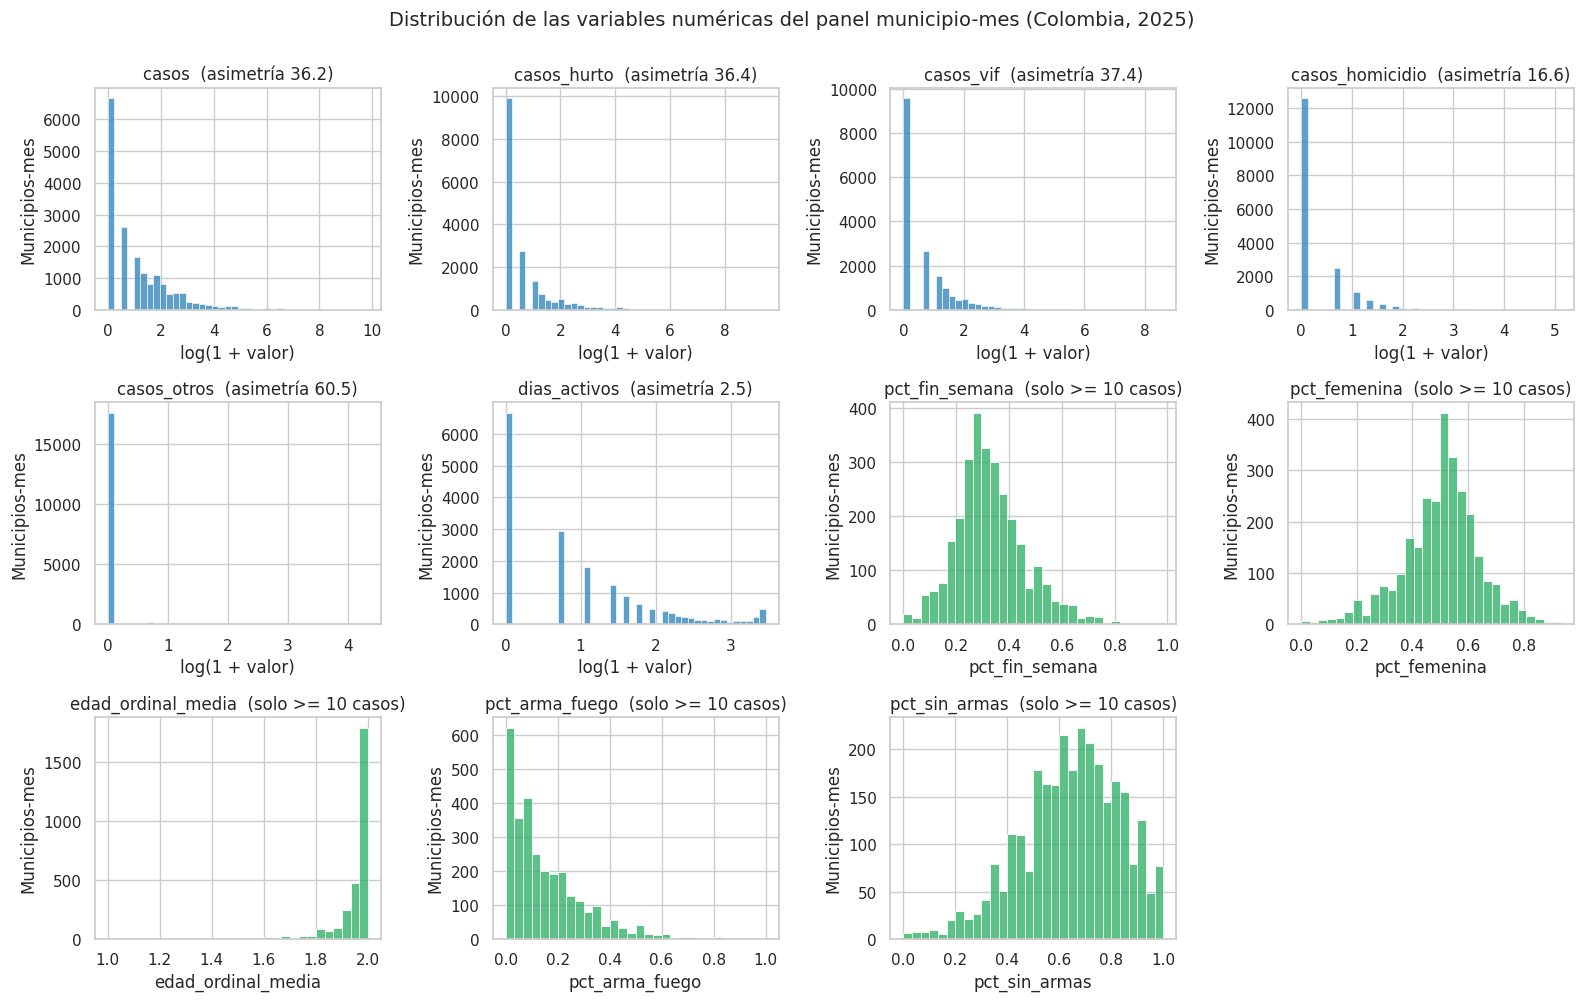

In [5]:
def zanahoria_2026_histogramas(df: pd.DataFrame, conteos: list[str], pcts: list[str], archivo: str) -> None:
    """ZANAHORIA_2026: dibuja una rejilla de histogramas (conteos en log1p y porcentajes con >= 10 casos)."""
    fig, ejes = plt.subplots(3, 4, figsize=(16, 10))
    ejes = ejes.ravel()
    for i, col in enumerate(conteos):
        sns.histplot(np.log1p(df[col]), bins=40, ax=ejes[i], color="#2980b9")
        ejes[i].set(title=f"{col}  (asimetría {df[col].skew():.1f})", xlabel="log(1 + valor)", ylabel="Municipios-mes")
    estables = df[df["casos"] >= 10]
    for j, col in enumerate(pcts):
        sns.histplot(estables[col].dropna(), bins=30, ax=ejes[len(conteos) + j], color="#27ae60")
        ejes[len(conteos) + j].set(title=f"{col}  (solo >= 10 casos)", xlabel=col, ylabel="Municipios-mes")
    for k in range(len(conteos) + len(pcts), len(ejes)):
        ejes[k].axis("off")
    fig.suptitle("Distribución de las variables numéricas del panel municipio-mes (Colombia, 2025)", y=1.0, fontsize=14)
    plt.tight_layout()
    plt.savefig(CARPETA_FIGURAS / archivo, dpi=130, bbox_inches="tight")
    plt.show()

zanahoria_2026_histogramas(zanahoria_2026_df_eda, cols_conteo, cols_pct, "zanahoria_2026_histogramas.png")

In [6]:
estables = zanahoria_2026_df_eda[zanahoria_2026_df_eda["casos"] >= 10]
print("Medianas con >= 10 casos:", estables[cols_pct].median().round(3).to_dict())
print("Mediana de casos por municipio-mes:", zanahoria_2026_df_eda["casos"].median(), "| media:", round(zanahoria_2026_df_eda["casos"].mean(), 1))
print("Máximo:", zanahoria_2026_df_eda["casos"].max())

Medianas con >= 10 casos: {'pct_fin_semana': 0.312, 'pct_femenina': 0.505, 'edad_ordinal_media': 1.988, 'pct_arma_fuego': 0.1, 'pct_sin_armas': 0.655}
Mediana de casos por municipio-mes: 1.0 | media: 26.7
Máximo: 18567


**Insight:** en un municipio-mes típico se registra **1 solo caso** (mediana), pero el promedio es 26,7 y el máximo 18 567: la mayoría de municipios es pequeña y unos pocos concentran el delito. Además, el 37 % de las celdas municipio-mes no tiene ningún caso y solo el 16 % supera los 10. En cambio, los porcentajes (cuando hay 10 o más casos) tienen forma de campana: el delito ocurre en fin de semana en ~31 % de los casos (casi lo que daría repartirlo parejo entre 7 días: 29 %), la mitad de las víctimas son mujeres y casi todas son adultas.

## 4. Boxplots para detectar atípicos

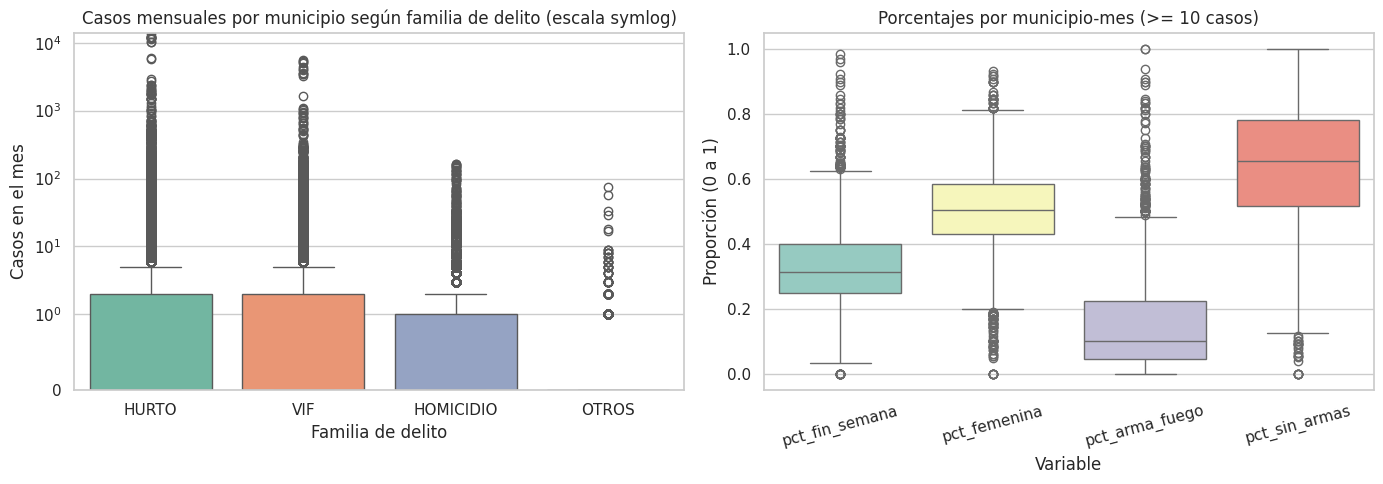

In [7]:
largo = zanahoria_2026_df_eda.melt(
    id_vars=["dane"], value_vars=["casos_hurto", "casos_vif", "casos_homicidio", "casos_otros"],
    var_name="familia", value_name="casos_mes",
)
largo["familia"] = largo["familia"].str.replace("casos_", "").str.upper()

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=largo, x="familia", y="casos_mes", ax=ejes[0], palette="Set2", hue="familia", legend=False)
ejes[0].set_yscale("symlog", linthresh=1)
ejes[0].set_ylim(0, None)
ejes[0].set(title="Casos mensuales por municipio según familia de delito (escala symlog)", xlabel="Familia de delito", ylabel="Casos en el mes")
sns.boxplot(data=zanahoria_2026_df_eda[zanahoria_2026_df_eda["casos"] >= 10][cols_pct[:2] + cols_pct[3:]],
            ax=ejes[1], palette="Set3")
ejes[1].set(title="Porcentajes por municipio-mes (>= 10 casos)", xlabel="Variable", ylabel="Proporción (0 a 1)")
ejes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_boxplots.png", dpi=130)
plt.show()

In [8]:
def zanahoria_2026_pct_atipicos(s: pd.Series) -> float:
    """ZANAHORIA_2026: porcentaje de valores fuera de 1.5 x IQR."""
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).mean() * 100

tabla_atipicos = pd.DataFrame({
    "% atípicos IQR": zanahoria_2026_df_eda[cols_conteo].apply(zanahoria_2026_pct_atipicos),
    "máximo": zanahoria_2026_df_eda[cols_conteo].max(),
    "mediana": zanahoria_2026_df_eda[cols_conteo].median(),
})
tabla_atipicos

,% atípicos IQR,máximo,mediana
casos,12.672,18567,1.000
casos_hurto,13.467,13323,0.000
casos_vif,11.978,5484,0.000
casos_homicidio,10.228,166,0.000
casos_otros,2.078,75,0.000
dias_activos,11.144,31,1.000


In [9]:
top_pico = zanahoria_2026_df_eda.loc[zanahoria_2026_df_eda.groupby("municipio")["casos"].idxmax()].nlargest(6, "casos")[["municipio", "departamento", "mes", "casos"]]
top_pico

,municipio,departamento,mes,casos
2925,BOGOTÁ D.C.,CUNDINAMARCA,10,18567
9,MEDELLÍN,ANTIOQUIA,10,3938
16485,CALI,VALLE,10,2402
2529,BARRANQUILLA,ATLÁNTICO,10,1480
2928,CARTAGENA,BOLÍVAR,1,1066
9249,SOACHA,CUNDINAMARCA,10,959


**Insight:** cerca del 13 % de los municipios-mes son "atípicos" por IQR, pero no son errores: los extremos son Bogotá (18 567 casos en octubre), Medellín (3 938), Cali (2 402) y Barranquilla (1 480), es decir, **las ciudades donde de verdad hay más delito**. Borrarlos eliminaría justamente lo que interesa predecir, así que en la Fase B se conservan y se controlan con transformación logarítmica y escalado robusto.

## 5. Correlaciones (Pearson y Spearman)
**Pearson** mide relación lineal y es muy sensible a los extremos (Bogotá); **Spearman** usa rangos y
mide si "cuando una sube, la otra también", sin importar la forma. Comparar ambos revela qué tanto
de la correlación depende de unos pocos municipios gigantes.

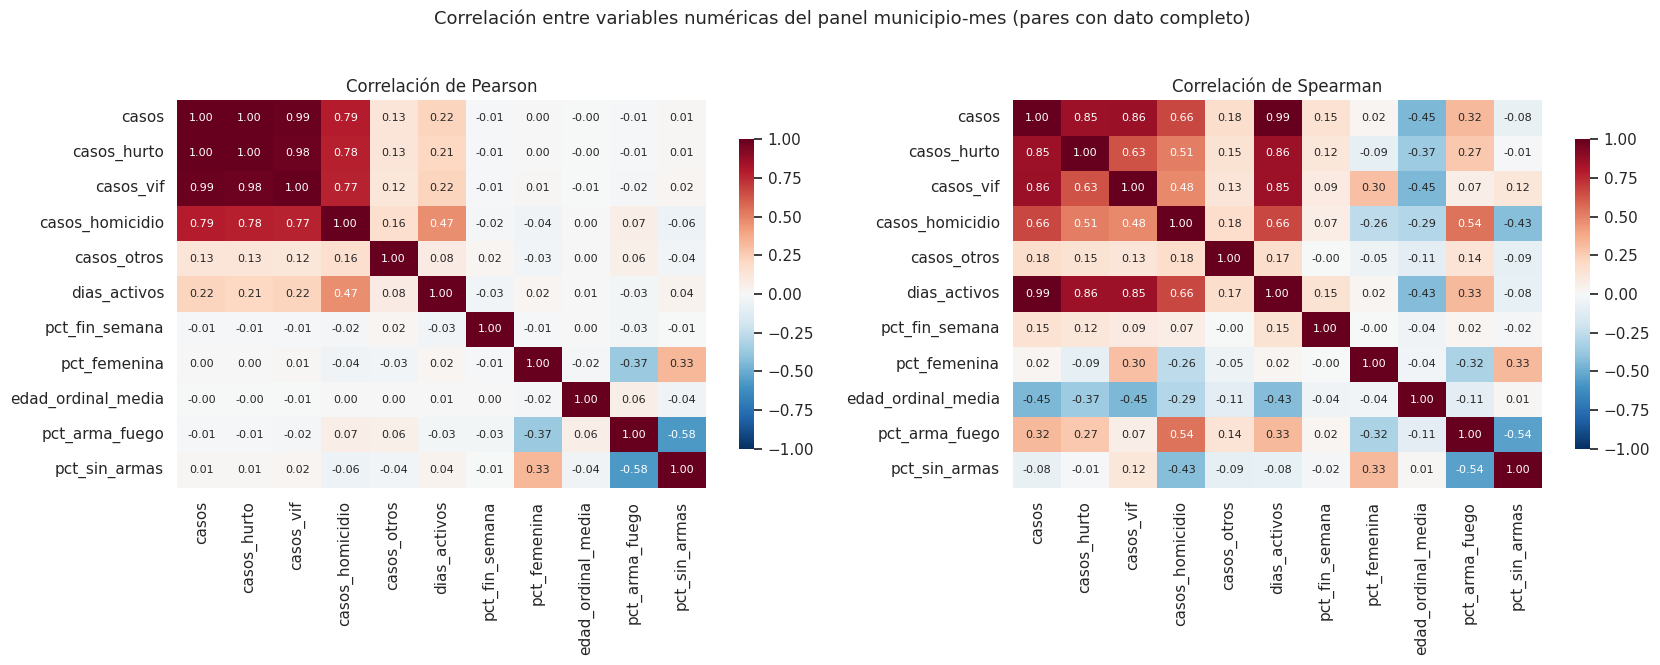

In [10]:
variables_corr = cols_conteo + cols_pct
fig, ejes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, metodo in zip(ejes, ["pearson", "spearman"]):
    corr = zanahoria_2026_df_eda[variables_corr].corr(method=metodo)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8}, cbar_kws={"shrink": 0.8})
    ax.set_title(f"Correlación de {metodo.capitalize()}")
plt.suptitle("Correlación entre variables numéricas del panel municipio-mes (pares con dato completo)", y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_heatmap_correlacion.png", dpi=130, bbox_inches="tight")
plt.show()

In [11]:
pearson = zanahoria_2026_df_eda[variables_corr].corr("pearson")
spearman = zanahoria_2026_df_eda[variables_corr].corr("spearman")
print("casos vs casos_hurto  (P/S):", round(pearson.loc["casos", "casos_hurto"], 3), round(spearman.loc["casos", "casos_hurto"], 3))
print("casos vs dias_activos (P/S):", round(pearson.loc["casos", "dias_activos"], 3), round(spearman.loc["casos", "dias_activos"], 3))
print("casos vs casos_vif    (P/S):", round(pearson.loc["casos", "casos_vif"], 3), round(spearman.loc["casos", "casos_vif"], 3))
print("casos vs casos_otros  (P/S):", round(pearson.loc["casos", "casos_otros"], 3), round(spearman.loc["casos", "casos_otros"], 3))
print("pct_femenina vs pct_sin_armas (P/S):", round(pearson.loc["pct_femenina", "pct_sin_armas"], 3), round(spearman.loc["pct_femenina", "pct_sin_armas"], 3))
print("pct_arma_fuego vs pct_sin_armas (P/S):", round(pearson.loc["pct_arma_fuego", "pct_sin_armas"], 3), round(spearman.loc["pct_arma_fuego", "pct_sin_armas"], 3))
print("pct_femenina vs pct_arma_fuego (P/S):", round(pearson.loc["pct_femenina", "pct_arma_fuego"], 3), round(spearman.loc["pct_femenina", "pct_arma_fuego"], 3))
print("casos vs pct_fin_semana (P/S):", round(pearson.loc["casos", "pct_fin_semana"], 3), round(spearman.loc["casos", "pct_fin_semana"], 3))
print("casos vs pct_femenina (P/S):", round(pearson.loc["casos", "pct_femenina"], 3), round(spearman.loc["casos", "pct_femenina"], 3))
print("dif absoluta máxima Pearson vs Spearman:", round((pearson - spearman).abs().max().max(), 3))

casos vs casos_hurto  (P/S): 0.998 0.852
casos vs dias_activos (P/S): 0.22 0.995
casos vs casos_vif    (P/S): 0.988 0.859
casos vs casos_otros  (P/S): 0.132 0.178
pct_femenina vs pct_sin_armas (P/S): 0.331 0.325
pct_arma_fuego vs pct_sin_armas (P/S): -0.577 -0.544
pct_femenina vs pct_arma_fuego (P/S): -0.369 -0.316
casos vs pct_fin_semana (P/S): -0.011 0.149
casos vs pct_femenina (P/S): 0.004 0.018
dif absoluta máxima Pearson vs Spearman: 0.775


**Insight:** Pearson y Spearman cuentan historias distintas. Pearson dice que `casos` y `dias_activos` casi no se relacionan (0,22) porque Bogotá, con sus 31 días activos y miles de casos, arrastra la medición; Spearman revela que **sí están casi perfectamente ordenados (0,99)**: donde hay más casos, hay delito más días. Los porcentajes de perfil (género, arma, fin de semana) son prácticamente independientes del volumen (|r| ≈ 0), pero se amarran entre sí: donde hay más arma de fuego hay menos "sin armas" (−0,58) y menos víctimas mujeres (−0,37), un reflejo de que la violencia intrafamiliar y el homicidio son dos mundos distintos.

## 6. Gráficos adicionales con insight de negocio
### 6.1 Pareto: ¿qué tan concentrado está el delito en pocos municipios?

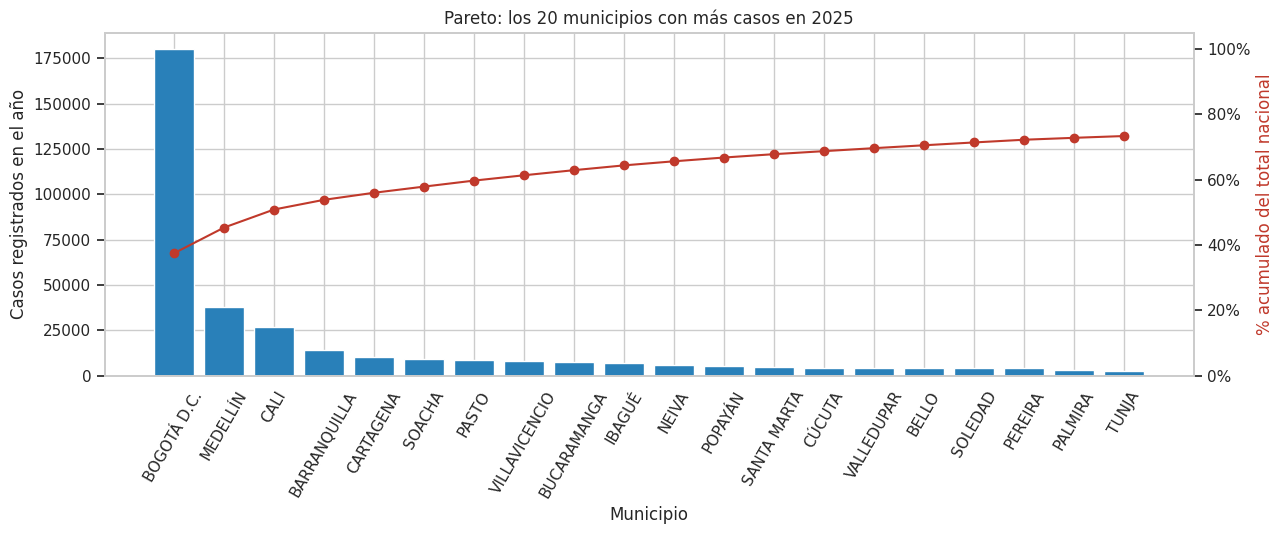

In [12]:
por_municipio = (zanahoria_2026_df_eda.groupby(["dane", "municipio", "departamento"])["casos"].sum().sort_values(ascending=False).reset_index())
por_municipio["acumulado_pct"] = por_municipio["casos"].cumsum() / por_municipio["casos"].sum() * 100
top20 = por_municipio.head(20)

fig, ax1 = plt.subplots(figsize=(13, 5.5))
ax1.bar(top20["municipio"], top20["casos"], color="#2980b9")
ax1.set(title="Pareto: los 20 municipios con más casos en 2025", xlabel="Municipio", ylabel="Casos registrados en el año")
ax1.tick_params(axis="x", rotation=60)
ax2 = ax1.twinx()
ax2.plot(top20["municipio"], top20["acumulado_pct"], color="#c0392b", marker="o")
ax2.set_ylim(0, 105)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.set_ylabel("% acumulado del total nacional", color="#c0392b")
ax2.grid(False)
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_pareto_municipios.png", dpi=130)
plt.show()

In [13]:
total = por_municipio["casos"].sum()
print(f"Bogotá: {por_municipio.iloc[0]['casos']:,} casos = {por_municipio.iloc[0]['casos'] / total:.1%} del total")
for n in [5, 10, 20, 50, 150]:
    print(f"Top {n:>3} municipios: {por_municipio['acumulado_pct'].iloc[n - 1]:.1f}% de los casos")
n80 = int((por_municipio["acumulado_pct"] < 80).sum() + 1)
print(f"Municipios necesarios para el 80% de los casos: {n80} de {len(por_municipio)} ({n80 / len(por_municipio):.1%})")
print(f"Municipios con menos de 20 casos en el año: {(por_municipio['casos'] < 20).sum()} ({(por_municipio['casos'] < 20).mean():.1%})")

Bogotá: 179,963 casos = 37.5% del total
Top   5 municipios: 56.0% de los casos
Top  10 municipios: 64.4% de los casos
Top  20 municipios: 73.4% de los casos
Top  50 municipios: 82.9% de los casos
Top 150 municipios: 91.2% de los casos
Municipios necesarios para el 80% de los casos: 39 de 1500 (2.6%)
Municipios con menos de 20 casos en el año: 757 (50.5%)


**Insight:** **Bogotá sola concentra el 37,5 % de todos los casos del país**, los 5 municipios principales suman el 56 % y bastan **39 de 1 500 municipios (2,6 %) para llegar al 80 %**. En el otro extremo, la mitad de los municipios (757) registra menos de 20 casos en todo el año. Para la política pública esto significa que las intervenciones de alto impacto caben en pocas ciudades, y para el modelado que un solo error en Bogotá pesa más que cientos de municipios pequeños.

### 6.2 Serie de tiempo: ¿cómo evolucionó cada familia de delito durante 2025?

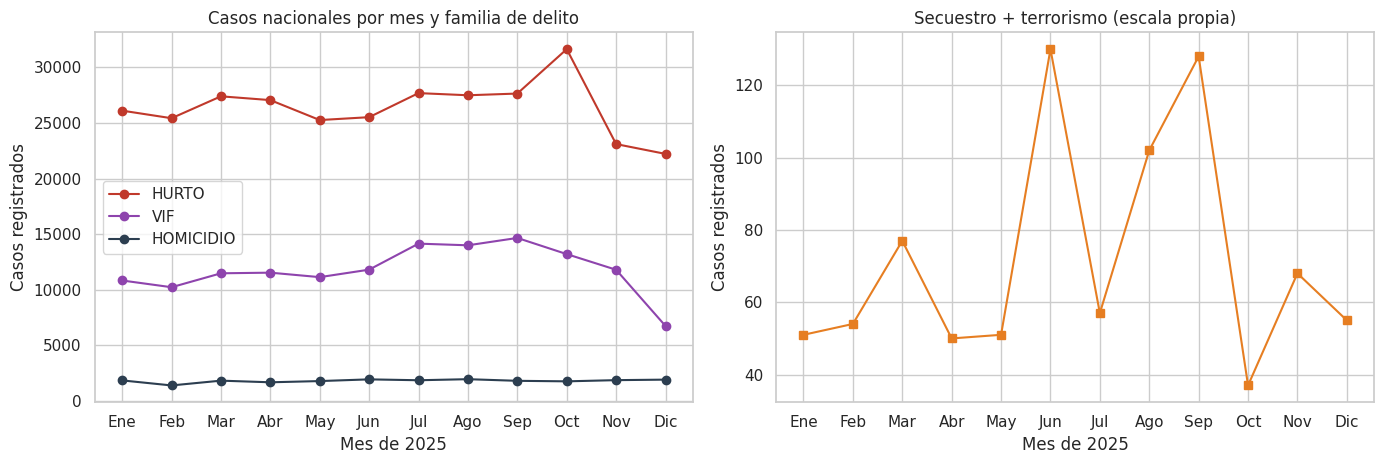

In [14]:
mensual = zanahoria_2026_df_eda.groupby("mes")[["casos_hurto", "casos_vif", "casos_homicidio", "casos_otros", "casos"]].sum()
nombres_mes = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8))
for col, color in zip(["casos_hurto", "casos_vif", "casos_homicidio"], ["#c0392b", "#8e44ad", "#2c3e50"]):
    ejes[0].plot(nombres_mes, mensual[col], marker="o", label=col.replace("casos_", "").upper(), color=color)
ejes[0].set(title="Casos nacionales por mes y familia de delito", xlabel="Mes de 2025", ylabel="Casos registrados")
ejes[0].legend()
ejes[1].plot(nombres_mes, mensual["casos_otros"], marker="s", color="#e67e22")
ejes[1].set(title="Secuestro + terrorismo (escala propia)", xlabel="Mes de 2025", ylabel="Casos registrados")
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_serie_mensual.png", dpi=130)
plt.show()

In [15]:
print(mensual[["casos", "casos_hurto", "casos_vif", "casos_homicidio", "casos_otros"]])
print("Pico:", nombres_mes[int(mensual['casos'].idxmax()) - 1], int(mensual['casos'].max()), "| Mínimo:", nombres_mes[int(mensual['casos'].idxmin()) - 1], int(mensual['casos'].min()))
print("Dic vs Oct: ", f"{mensual.loc[12, 'casos'] / mensual.loc[10, 'casos'] - 1:.1%}", "| Nov vs Oct:", f"{mensual.loc[11, 'casos'] / mensual.loc[10, 'casos'] - 1:.1%}")
print("VIF Dic vs Oct:", f"{mensual.loc[12, 'casos_vif'] / mensual.loc[10, 'casos_vif'] - 1:.1%}", "| Hurto Dic vs Oct:", f"{mensual.loc[12, 'casos_hurto'] / mensual.loc[10, 'casos_hurto'] - 1:.1%}")

     casos  casos_hurto  casos_vif  casos_homicidio  casos_otros
mes                                                             
1    38792        26113      10814             1814           51
2    37054        25431      10208             1361           54
3    40735        27404      11462             1792           77
4    40275        27062      11519             1644           50
5    38187        25266      11116             1754           51
6    39353        25525      11790             1908          130
7    43712        27693      14134             1828           57
8    43509        27499      13984             1924          102
9    44205        27653      14647             1777          128
10   46611        31653      13191             1730           37
11   36786        23101      11780             1837           68
12   30872        22217       6716             1884           55
Pico: Oct 46611 | Mínimo: Dic 30872
Dic vs Oct:  -33.8% | Nov vs Oct: -21.1%
VIF Dic vs Oc

**Insight:** los casos registrados suben de ~38 mil en enero a un pico de **46 611 en octubre** y luego se desploman a 30 872 en diciembre (−34 % frente a octubre). Pero los homicidios se mantienen planos (entre 1 700 y 1 900 cada mes, incluyendo diciembre) mientras la violencia intrafamiliar cae 49 % y el hurto 30 %. Como los homicidios se registran de inmediato y los otros delitos dependen de denuncias que se consolidan con retraso, la caída de fin de año parece **rezago en el reporte, no una baja real del delito** (ya se había advertido como limitación en el Proyecto 1).

### 6.3 Dispersión: ¿el mes anterior dice algo del mes siguiente?
Esta es la pregunta que motiva el modelo de la Fase C: si el nivel de un municipio es persistente,
se puede proyectar el siguiente mes.

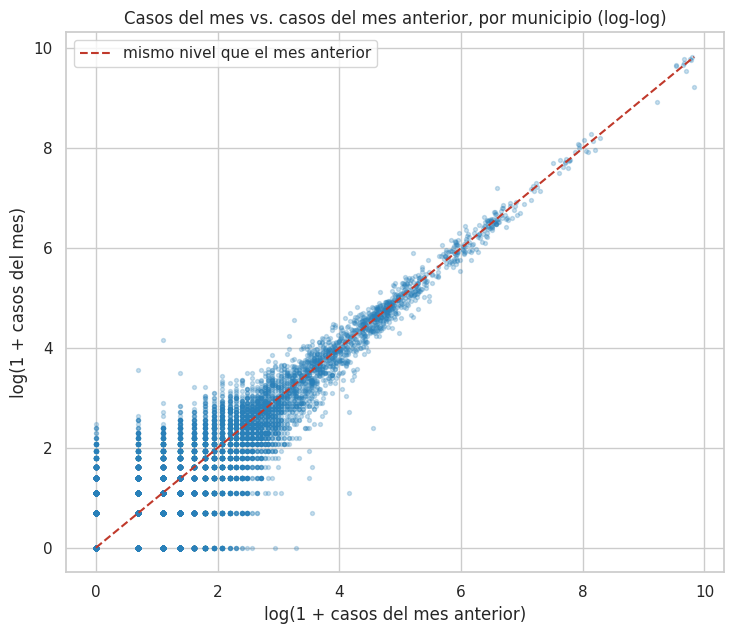

In [16]:
panel_orden = zanahoria_2026_df_eda.sort_values(["dane", "mes"]).copy()
panel_orden["casos_mes_anterior"] = panel_orden.groupby("dane")["casos"].shift(1)
disp = panel_orden.dropna(subset=["casos_mes_anterior"])

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.scatter(np.log1p(disp["casos_mes_anterior"]), np.log1p(disp["casos"]), s=8, alpha=0.25, color="#2980b9")
maximo = np.log1p(disp[["casos", "casos_mes_anterior"]].max().max())
ax.plot([0, maximo], [0, maximo], color="#c0392b", ls="--", label="mismo nivel que el mes anterior")
ax.set(title="Casos del mes vs. casos del mes anterior, por municipio (log-log)", xlabel="log(1 + casos del mes anterior)", ylabel="log(1 + casos del mes)")
ax.legend()
plt.tight_layout()
plt.savefig(CARPETA_FIGURAS / "zanahoria_2026_dispersion_persistencia.png", dpi=130)
plt.show()

In [17]:
r_log = np.corrcoef(np.log1p(disp["casos_mes_anterior"]), np.log1p(disp["casos"]))[0, 1]
r_raw = np.corrcoef(disp["casos_mes_anterior"], disp["casos"])[0, 1]
print(f"Correlación mes vs. mes anterior -> escala original: {r_raw:.3f} | log: {r_log:.3f} | R2 log aprox: {r_log**2:.3f}")
sin_caso_antes = disp[disp["casos_mes_anterior"] == 0]
print(f"Cuando el mes anterior fue 0: {len(sin_caso_antes):,} filas; el mes siguiente tuvo 0 casos en {(sin_caso_antes['casos'] == 0).mean():.1%}")

Correlación mes vs. mes anterior -> escala original: 0.983 | log: 0.896 | R2 log aprox: 0.802
Cuando el mes anterior fue 0: 6,031 filas; el mes siguiente tuvo 0 casos en 71.4%


**Insight:** los municipios son muy persistentes: los casos de un mes explican cerca del 80 % de la variación del mes siguiente en escala log (correlación 0,90; 0,98 en escala original, dominada por las grandes ciudades). Cuando el mes anterior fue 0, el siguiente también fue 0 en el 71 % de los casos. Esto hace viable **proyectar el siguiente mes**, pero también obliga a que el modelo demuestre que mejora frente a la regla ingenua "repetir el mes anterior".

## 7. Los 3 hallazgos más importantes
#
**1. El delito está extremadamente concentrado.** Bogotá reúne el 37,5 % de los casos y 39 municipios
(2,6 %) suman el 80 %; la mitad de los municipios tiene menos de 20 casos al año. Las distribuciones tienen
asimetrías de 16 a 60, por lo que el análisis y el modelado exigen transformación logarítmica, escalado
robusto y métricas que no estén dominadas por una sola ciudad.

**2. La caída de noviembre y diciembre parece un rezago de reporte.** Los casos totales bajan 34 % entre
octubre y diciembre, pero los homicidios (que se registran de inmediato) no se mueven. Cualquier modelo
que use esos meses debe leerse con cautela, y una validación temporal es indispensable.

**3. El mes anterior es un excelente predictor del siguiente.** La correlación en escala log es 0,90.
Esto habilita una **proyección mensual de casos por municipio**, que será el problema supervisado de la
Fase C (variable objetivo: casos del mes), y fija un piso que los modelos deben superar:
la regla "repetir el mes anterior".

*Pasos siguientes:* la Fase B limpia y transforma estos datos sin fuga de información; la Fase C los modela.